# 05 XGBoost
Gradient boosting ที่ใช้ทั้ง gradient และ hessian: ค่าใบ = `-ΣG / (ΣH + λ)`
แบ่งต่อเมื่อ gain มากกว่า regularisation สุ่มแถว 80% และคอลัมน์ 80% ต่อต้น

โค้ด: `Model/Classification/XGB.py`  
ผลลัพธ์: `Results/Classification/05_XGBoost/`

## 1. เตรียมข้อมูล

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "Model", "Common")))

import numpy as np
import pandas as pd
from project import SEED, Outputs, classification_data
from metrics_classification import roc_auc
from model_zoo import check_settings
from report_classification import report_classifier, sklearn_check
from XGB import XGBClassifierScratch
from xgboost import XGBClassifier
import plots

out = Outputs("Classification", "05_XGBoost")
d = classification_data()
print(
    f"train {d.X_tr.shape} | validation {d.X_va.shape} | test {d.X_te.shape} | "
    f"{len(d.feature_cols)} features | {d.y.mean():.1%} defaulters"
)

train (5746, 27) | validation (1916, 27) | test (1916, 27) | 27 features | 16.0% defaulters


## 2. เทรนโมเดล

In [2]:
model = XGBClassifierScratch(
    n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, colsample_bytree=0.8, random_state=SEED
)
check_settings("XGBoost", model)
model.fit(d.X_tr, d.y_tr, eval_set=[(d.X_va, d.y_va)], feature_names=d.feature_cols, early_stopping_rounds=30)
p_te = model.predict_proba(d.X_te)[:, 1]

sk = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=SEED,
    eval_metric="logloss",
).fit(d.X_tr, d.y_tr)
p_sk = sk.predict_proba(d.X_te)[:, 1]
check = sklearn_check(
    "XGBoost vs real xgboost (same settings)",
    np.abs(p_te - p_sk).max(),
    roc_auc(d.y_te, p_te),
    roc_auc(d.y_te, p_sk),
    "max |dP|",
)

settings match Common/model_zoo.py (13 values checked)


## 3. ผลลัพธ์

                                  test set  at plain 0.5
threshold (chosen on validation)    0.2617        0.5000
log loss                            0.4561           NaN
accuracy                            0.5449        0.8210
precision                           0.2223        0.3603
recall / sensitivity                0.7443        0.1607
specificity                         0.5071           NaN
F1                                  0.3424        0.2222
ROC-AUC                             0.6845           NaN
PR-AUC                              0.2784           NaN
defaulters missed (FN)             78.0000           NaN

catches 74.4% of the 305 test defaulters (78 missed), flags 53.3% of applicants


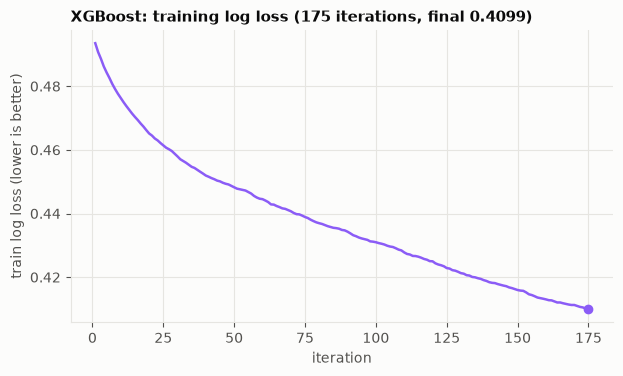

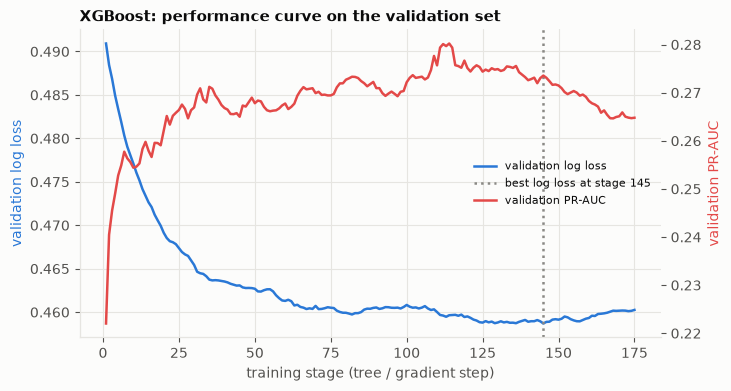

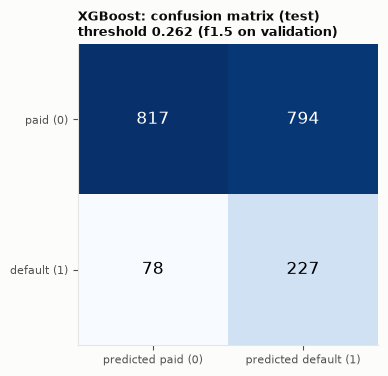

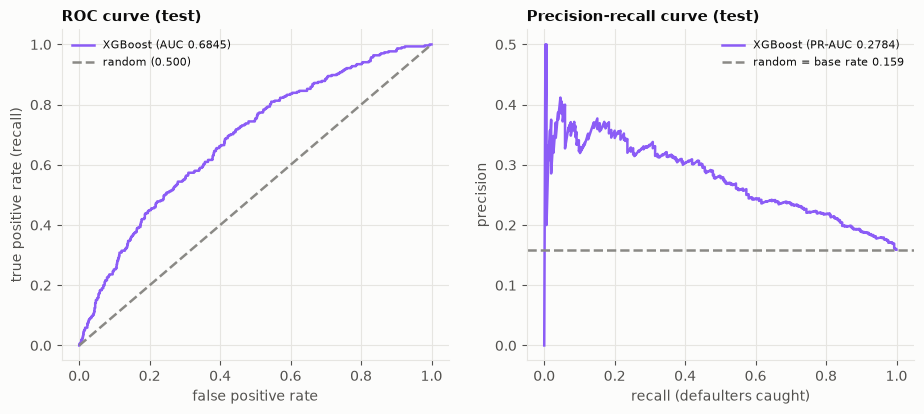

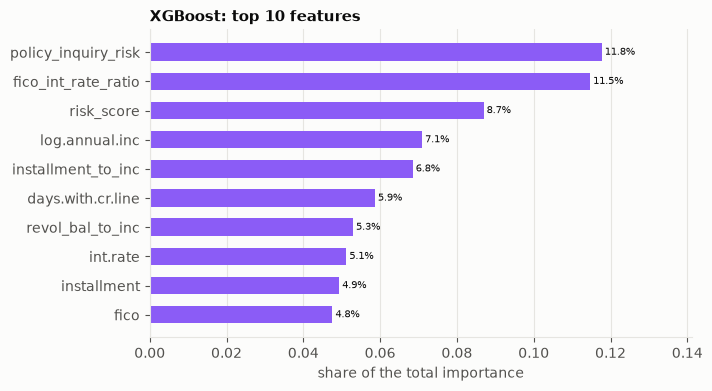


scratch vs library:
  XGBoost vs real xgboost (same settings)
    AUC scratch 0.6845 | AUC library 0.6722 | max |dP| = 0.31



saved + reloaded Results/Classification/05_XGBoost/model.joblib (identical predictions: True)



ROC-AUC drop when the feature is shuffled (top 8):
fico_int_rate_ratio    0.019497
policy_inquiry_risk    0.013838
risk_score             0.012426
log.annual.inc         0.011735
fico                   0.009592
purpose_credit_card    0.005806
installment_to_inc     0.004313
util_fico_mismatch     0.004286


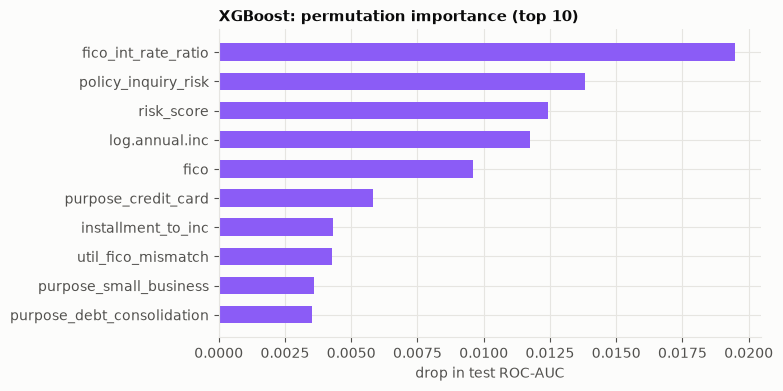

In [3]:
row = report_classifier(out, "XGBoost", model, d, check)

rng = np.random.RandomState(SEED)
base_auc = roc_auc(d.y_te, p_te)
drops = []
for j in range(d.X_te.shape[1]):
    loss = []
    for _ in range(3):
        Xp = d.X_te.copy()
        Xp[:, j] = Xp[rng.permutation(len(Xp)), j]
        loss.append(base_auc - roc_auc(d.y_te, model.predict_proba(Xp)[:, 1]))
    drops.append(float(np.mean(loss)))
perm = pd.Series(drops, index=d.feature_cols, name="roc_auc_drop").sort_values(ascending=False)
perm.to_csv(out.table("permutation_importance.csv"), index_label="feature")
print("\nROC-AUC drop when the feature is shuffled (top 8):")
print(perm.head(8).to_string())
fig, ax = plots.plt.subplots(figsize=(7, 4))
top = perm.head(10)[::-1]
ax.barh(top.index, top.values, color="#8b5cf6", height=0.6)
ax.set_xlabel("drop in test ROC-AUC")
ax.set_title("XGBoost: permutation importance (top 10)")
plots._save(fig, out.image("permutation_importance.png"))